# Teste com modelo KNN


## Import e Separação dos Dados

In [13]:
caminho = '../'

In [14]:
import pandas as pd
#Importar conjuntos de dados

df_dengue = pd.read_csv(caminho + 'database/Dengue.csv')
df_malaria= pd.read_csv(caminho + 'database/Malaria.csv')
df_shared = pd.read_csv(caminho + 'database/Shared.csv')

print(df_dengue.columns)
print(df_dengue['Result'].value_counts())

print(df_malaria.columns)
print(df_malaria['Result'].value_counts())

print(df_shared.columns)
print(df_shared['Result'].value_counts())

Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result', 'tipo'],
      dtype='object')
Result
0    928
1    671
Name: count, dtype: int64
Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result', 'tipo'],
      dtype='object')
Result
0    878
1    826
Name: count, dtype: int64
Index(['Hemoglobin(Hb%)', 'Total WBC count(/cumm)', 'Neutrophils',
       'Lymphocytes', 'Total Cir.Eosinophils', 'HTC/PCV(%)', 'MCH(pg)',
       'MCHC(g/dl)', 'RDW-CV(%)', 'Platelet Count', 'Result'],
      dtype='object')
Result
1    242
0    242
Name: count, dtype: int64


In [15]:
# Algumas coisinhas
tipo = df_malaria['tipo'].copy()

X = df_malaria.drop(columns=['Result', 'tipo'], axis=1).copy()
y = df_malaria['Result'].copy()

In [16]:
# Features e Labels
X_train = X[tipo == 'treino']
X_test  = X[tipo == 'teste']
X_val   = df_dengue.drop(columns=['Result', 'tipo'], axis=1).copy()
X_shared= df_shared.drop(columns=['Result'], axis=1).copy()

y_train = y[tipo == 'treino']
y_test  = y[tipo == 'teste']
y_val   = df_dengue['Result'].copy()
y_shared= df_shared['Result'].copy()

print(X_train.shape, X_test.shape, X_val.shape)
print(y_train.shape, y_test.shape, y_val.shape)

(1022, 10) (682, 10) (1599, 10)
(1022,) (682,) (1599,)


In [17]:
# Normalizar e Padronizar conjunto de dados
from sklearn.preprocessing import MinMaxScaler, StandardScaler

scaler_mim_max = MinMaxScaler()
scaler_mim_max.set_output(transform="pandas")

# Com MinMax Scaler
X_train = scaler_mim_max.fit_transform(X_train)
X_test  = scaler_mim_max.transform(X_test)
X_val   = scaler_mim_max.transform(X_val)
X_shared= scaler_mim_max.transform(X_shared)

## Testar no KNN Default

=== MÉTRICAS DE DESEMPENHO (KNN DEFAULT) ===

Acurácia: 0.6730
Precisão: 0.6777
Recall: 0.6750
F1-Score: 0.6723
MCC: 0.3527
AUC: 0.7088
--------------------------------------------------


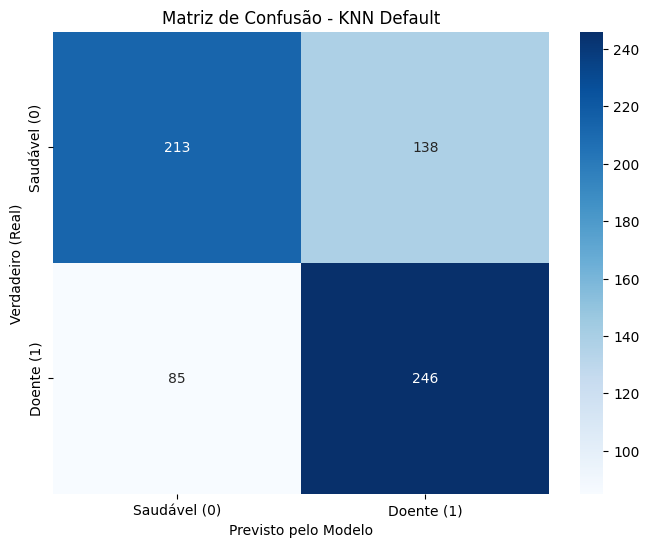

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             matthews_corrcoef, confusion_matrix)

# Criando e treinando o modelo KNN com parâmetros padrão (ex: k=5)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

# Fazendo as Previsões no conjunto de teste
y_pred_def = knn.predict(X_test)
y_prob_def = knn.predict_proba(X_test)[:, 1]

# Métricas
acuracia_def = accuracy_score(y_test, y_pred_def)
precisao_def = precision_score(y_test, y_pred_def, average='macro', zero_division=0)
recall_def = recall_score(y_test, y_pred_def, average='macro', zero_division=0)
f1_def = f1_score(y_test, y_pred_def, average='macro', zero_division=0)
mcc_def = matthews_corrcoef(y_test, y_pred_def)
auc = roc_auc_score(y_test, y_prob_def)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO (KNN DEFAULT) ===\n")
print(f"Acurácia: {acuracia_def:.4f}")
print(f"Precisão: {precisao_def:.4f}")
print(f"Recall: {recall_def:.4f}")
print(f"F1-Score: {f1_def:.4f}")
print(f"MCC: {mcc_def:.4f}")
print(f"AUC: {auc:.4f}")
print("-" * 50)

# Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_def)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])
plt.title('Matriz de Confusão - KNN Default')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

## Otimização de Hiperparâmetros

In [19]:
import optuna
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

def objective(trial):
    params = {
        'n_neighbors': trial.suggest_int('n_neighbors', 1, 30),
        'weights': trial.suggest_categorical('weights', ['uniform', 'distance']),
        'p': trial.suggest_int('p', 1, 10)
    }

    clf = KNeighborsClassifier(**params, n_jobs=-1)

    # Validação cruzada com F1-macro para avaliar o desempenho
    score = cross_val_score(clf, X_train, y_train.values.ravel(), scoring='f1_macro', cv=5, n_jobs=-1).mean()
    return score

# Criando e executando o estudo
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"Melhor pontuação (CV): {study.best_value:.4f}")
print("Melhores parâmetros:")
print(study.best_params)

# Treinando o modelo final com os melhores parâmetros encontrados
best_knn = KNeighborsClassifier(**study.best_params, n_jobs=-1)
best_knn.fit(X_train, y_train.values.ravel())

[I 2026-07-27 12:43:16,725] A new study created in memory with name: no-name-89ec3772-5299-4b79-8a73-2fa8de88a643
Best trial: 2. Best value: 0.659568:   7%|▋         | 2/30 [00:00<00:02, 13.34it/s]

[I 2026-07-27 12:43:16,812] Trial 0 finished with value: 0.6564167478248467 and parameters: {'n_neighbors': 20, 'weights': 'uniform', 'p': 5}. Best is trial 0 with value: 0.6564167478248467.
[I 2026-07-27 12:43:16,882] Trial 1 finished with value: 0.6318507180750059 and parameters: {'n_neighbors': 3, 'weights': 'uniform', 'p': 9}. Best is trial 0 with value: 0.6564167478248467.
[I 2026-07-27 12:43:16,953] Trial 2 finished with value: 0.6595684026310951 and parameters: {'n_neighbors': 28, 'weights': 'distance', 'p': 3}. Best is trial 2 with value: 0.6595684026310951.


Best trial: 2. Best value: 0.659568:  20%|██        | 6/30 [00:00<00:01, 14.60it/s]

[I 2026-07-27 12:43:17,013] Trial 3 finished with value: 0.64631215261339 and parameters: {'n_neighbors': 19, 'weights': 'distance', 'p': 8}. Best is trial 2 with value: 0.6595684026310951.
[I 2026-07-27 12:43:17,082] Trial 4 finished with value: 0.6463223777422012 and parameters: {'n_neighbors': 20, 'weights': 'uniform', 'p': 10}. Best is trial 2 with value: 0.6595684026310951.
[I 2026-07-27 12:43:17,144] Trial 5 finished with value: 0.6513156422918007 and parameters: {'n_neighbors': 26, 'weights': 'distance', 'p': 7}. Best is trial 2 with value: 0.6595684026310951.


Best trial: 7. Best value: 0.661178:  27%|██▋       | 8/30 [00:00<00:01, 14.48it/s]

[I 2026-07-27 12:43:17,213] Trial 6 finished with value: 0.6428324042001932 and parameters: {'n_neighbors': 25, 'weights': 'distance', 'p': 8}. Best is trial 2 with value: 0.6595684026310951.
[I 2026-07-27 12:43:17,287] Trial 7 finished with value: 0.6611783381418246 and parameters: {'n_neighbors': 25, 'weights': 'distance', 'p': 3}. Best is trial 7 with value: 0.6611783381418246.
[I 2026-07-27 12:43:17,359] Trial 8 finished with value: 0.6545311954806963 and parameters: {'n_neighbors': 11, 'weights': 'uniform', 'p': 7}. Best is trial 7 with value: 0.6611783381418246.


... (11 outputs left out)

[I 2026-07-27 12:43:18,468] Trial 26 finished with value: 0.6532478110982225 and parameters: {'n_neighbors': 17, 'weights': 'uniform', 'p': 4}. Best is trial 10 with value: 0.6894914872917506.
[I 2026-07-27 12:43:18,521] Trial 27 finished with value: 0.6563964798388044 and parameters: {'n_neighbors': 8, 'weights': 'distance', 'p': 2}. Best is trial 10 with value: 0.6894914872917506.
[I 2026-07-27 12:43:18,612] Trial 28 finished with value: 0.6661680092061598 and parameters: {'n_neighbors': 17, 'weights': 'distance', 'p': 3}. Best is trial 10 with value: 0.6894914872917506.


Best trial: 10. Best value: 0.689491: 100%|██████████| 30/30 [00:01<00:00, 15.13it/s]

[I 2026-07-27 12:43:18,710] Trial 29 finished with value: 0.6542017194216255 and parameters: {'n_neighbors': 22, 'weights': 'uniform', 'p': 6}. Best is trial 10 with value: 0.6894914872917506.
Melhor pontuação (CV): 0.6895
Melhores parâmetros:
{'n_neighbors': 12, 'weights': 'distance', 'p': 1}


,n_neighbors,12
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,1
,metric,'minkowski'
,metric_params,None
,n_jobs,-1


In [20]:
fig = optuna.visualization.plot_param_importances(study)
fig.show()

fig = optuna.visualization.plot_optimization_history(study)
fig.show()

=== MÉTRICAS DE DESEMPENHO ===

Acurácia: 0.6716
Precisão: 0.6817
Recall:   0.6746
F1-Score: 0.6692
MCC:      0.3563
AUC:      0.7187
--------------------------------------------------


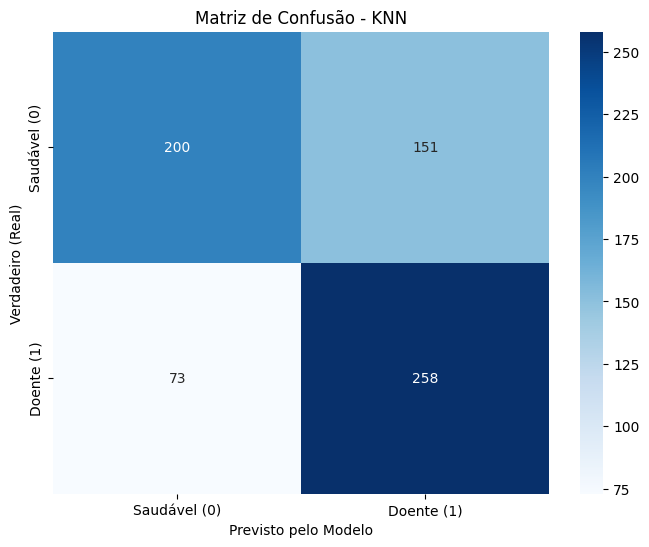

In [21]:
# Fazendo as Previsões
y_pred_best = best_knn.predict(X_test)
y_prob_best = best_knn.predict_proba(X_test)[:, 1]

# Métricas
acuracia_best = accuracy_score(y_test, y_pred_best)
precisao_best = precision_score(y_test, y_pred_best, average='macro')
recall_best   = recall_score(y_test, y_pred_best, average='macro')
f1_best       = f1_score(y_test, y_pred_best, average='macro')
mcc_best      = matthews_corrcoef(y_test, y_pred_best)

# O AUC binário recebe as classes reais e as probabilidades diretamente
auc = roc_auc_score(y_test, y_prob_best)

# Exibindo os Resultados
print("=== MÉTRICAS DE DESEMPENHO ===\n")
print(f"Acurácia: {acuracia_best:.4f}")
print(f"Precisão: {precisao_best:.4f}")
print(f"Recall:   {recall_best:.4f}")
print(f"F1-Score: {f1_best:.4f}")
print(f"MCC:      {mcc_best:.4f}")
print(f"AUC:      {auc:.4f}")
print("-" * 50)


# 5. Plotando a Matriz de Confusão
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred_best)

# Labels ajustados exclusivamente para as duas doenças
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])

plt.title('Matriz de Confusão - KNN')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

# Validação Externa

=== VALIDAÇÃO EXTERNA (KNN OTIMIZADO) ===

Acurácia: 0.7348
Precisão: 0.7476
Recall: 0.7507
F1-Score: 0.7347
MCC: 0.4983
AUC: 0.8144
--------------------------------------------------


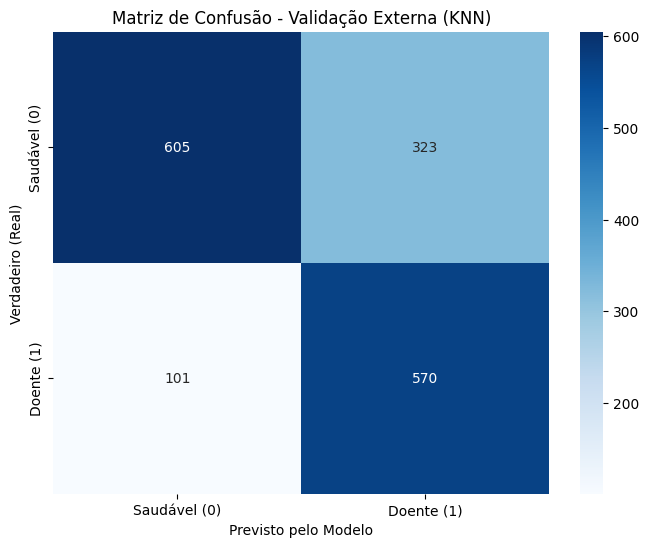

In [22]:
import numpy as np

y_true_val = np.array(y_val).ravel()
y_pred_val = best_knn.predict(X_val)
y_prob_val = best_knn.predict_proba(X_val)[:, 1]

# Métricas na Validação Externa
acuracia_val = accuracy_score(y_true_val, y_pred_val)
precisao_val = precision_score(y_true_val, y_pred_val, average='macro', zero_division=0)
recall_val = recall_score(y_true_val, y_pred_val, average='macro', zero_division=0)
f1_val = f1_score(y_true_val, y_pred_val, average='macro', zero_division=0)
mcc_val = matthews_corrcoef(y_true_val, y_pred_val)
auc_val = roc_auc_score(y_true_val, y_prob_val)

print("=== VALIDAÇÃO EXTERNA (KNN OTIMIZADO) ===\n")
print(f"Acurácia: {acuracia_val:.4f}")
print(f"Precisão: {precisao_val:.4f}")
print(f"Recall: {recall_val:.4f}")
print(f"F1-Score: {f1_val:.4f}")
print(f"MCC: {mcc_val:.4f}")
print(f"AUC: {auc_val:.4f}")
print("-" * 50)

# Matriz de Confusão Externa
plt.figure(figsize=(8, 6))
cm_val = confusion_matrix(y_true_val, y_pred_val)
sns.heatmap(cm_val, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])
plt.title('Matriz de Confusão - Validação Externa (KNN)')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

=== VALIDAÇÃO EXTERNA SHARED ===

Acurácia: 0.7603
Precisão: 0.7719
Recall: 0.7603
F1-Score: 0.7577
MCC: 0.5321
AUC: 0.8013
--------------------------------------------------


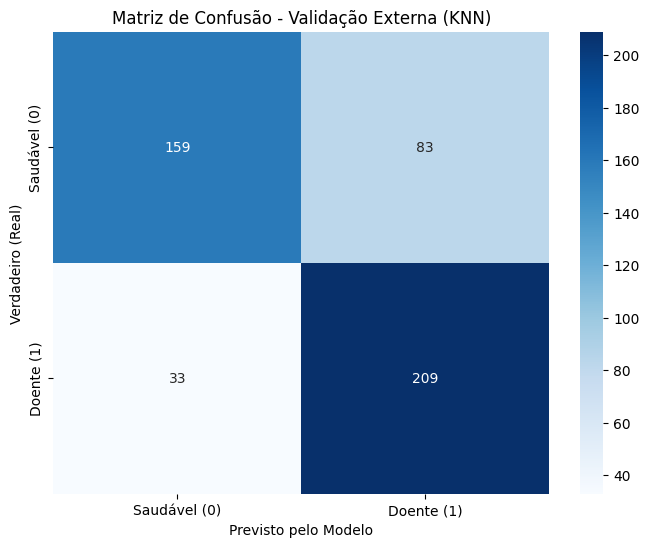

In [23]:
import numpy as np

y_true_shared = np.array(y_shared).ravel()
y_pred_shared = best_knn.predict(X_shared)
y_prob_shared = best_knn.predict_proba(X_shared)[:, 1]

# Métricas na Validação Externa
acuracia_shared = accuracy_score(y_true_shared, y_pred_shared)
precisao_shared = precision_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
recall_shared = recall_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
f1_shared = f1_score(y_true_shared, y_pred_shared, average='macro', zero_division=0)
mcc_shared = matthews_corrcoef(y_true_shared, y_pred_shared)
auc_shared = roc_auc_score(y_true_shared, y_prob_shared)

print("=== VALIDAÇÃO EXTERNA SHARED ===\n")
print(f"Acurácia: {acuracia_shared:.4f}")
print(f"Precisão: {precisao_shared:.4f}")
print(f"Recall: {recall_shared:.4f}")
print(f"F1-Score: {f1_shared:.4f}")
print(f"MCC: {mcc_shared:.4f}")
print(f"AUC: {auc_shared:.4f}")
print("-" * 50)

# Matriz de Confusão Externa
plt.figure(figsize=(8, 6))
cm_shared = confusion_matrix(y_true_shared, y_pred_shared)
sns.heatmap(cm_shared, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Saudável (0)', 'Doente (1)'],
            yticklabels=['Saudável (0)', 'Doente (1)'])
plt.title('Matriz de Confusão - Validação Externa (KNN)')
plt.xlabel('Previsto pelo Modelo')
plt.ylabel('Verdadeiro (Real)')
plt.show()

In [24]:
import pandas as pd

# Mude apenas o nome do modelo aqui
nome_modelo = 'knn'

arquivo_pred = caminho + 'treino_malaria/saidas/predicoes.csv'
arquivo_proba = caminho + 'treino_malaria/saidas/probabilidades.csv'


# Cria uma lista começando com o nome, o conjunto e depois todas as predições
linha_pred_teste = [nome_modelo, 'teste'] + list(y_pred_best)
linha_pred_val = [nome_modelo, 'validacao'] + list(y_pred_val)
linha_pred_shared = [nome_modelo, 'shared'] + list(y_pred_shared)


# Salva adicionando as linhas embaixo (mode='a') sem cabeçalho
pd.DataFrame([linha_pred_teste, linha_pred_val, linha_pred_shared]).to_csv(arquivo_pred, mode='a', header=False, index=False)


# Probas
linha_proba_teste = [nome_modelo, 'teste'] + list(y_prob_best)
linha_proba_val = [nome_modelo, 'validacao'] + list(y_prob_val)
linha_proba_shared = [nome_modelo, 'shared'] + list(y_prob_shared)

pd.DataFrame([linha_proba_teste, linha_proba_val, linha_proba_shared]).to_csv(arquivo_proba, mode='a', header=False, index=False)

print(f"Linhas do modelo {nome_modelo} adicionadas com sucesso!")

Linhas do modelo knn adicionadas com sucesso!
